# Las losowy – case study: odejścia klientów (Churn)

**Plan notatnika:**
1. Dane i przygotowanie
2. Pojedyncze drzewo a las losowy
3. Macierz pomyłek i próg decyzyjny
4. Ważność cech
5. Dobór hiperparametrów (`RandomizedSearchCV`)
6. Podsumowanie

W rozdziale 4.1 zbudowaliśmy drzewo przewidujące odejście klienta (`churn`) firmy telekomunikacyjnej. Teraz sprawdzimy, czy **las losowy** poradzi sobie lepiej. Dane są niezbalansowane (ok. 14,5% odejść), więc oprócz `accuracy` patrzymy na **precision, recall, F1 i ROC-AUC**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import randint
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


## 1. Dane i przygotowanie

Przygotowanie jest takie samo jak w rozdziale 4.1: usuwamy identyfikatory (`phone number`) i kolumny o wielu kategoriach (`state`, `area code`), kodujemy cechy `yes`/`no` i dzielimy dane **tak samo** (`random_state=42`, `stratify=y`), dzięki czemu wyniki są porównywalne z 4.1.

In [2]:
df = pd.read_csv('churn.csv')

X = df.drop(columns=['state', 'area code', 'phone number', 'churn'])
X = pd.get_dummies(X, drop_first=True, dtype=int)
y = df['churn'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print('Zbiór treningowy:', X_train.shape, '  testowy:', X_test.shape)
print('Udział klienta odchodzącego w zbiorze testowym:', round(y_test.mean(), 3))

Zbiór treningowy: (2499, 17)   testowy: (834, 17)
Udział klienta odchodzącego w zbiorze testowym: 0.145


## 2. Pojedyncze drzewo a las losowy

Porównamy:
- **baseline** – zawsze klasa najczęstsza,
- **drzewo** z `max_depth=3` (jak w 4.1) i **drzewo bez ograniczeń**,
- **las losowy** z ustawieniami domyślnymi,
- **las losowy** z `class_weight='balanced_subsample'` (większa waga rzadkiej klasy w każdej próbce bootstrap).

In [5]:
def metryki(nazwa, model):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {'model': nazwa,
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred, zero_division=0),
            'recall': recall_score(y_test, y_pred),
            'F1': f1_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_proba)}

modele = {
    'baseline': DummyClassifier(strategy='most_frequent'),
    'drzewo max_depth=3': DecisionTreeClassifier(max_depth=3, random_state=42),
    'drzewo bez limitu': DecisionTreeClassifier(random_state=42),
    'las losowy': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "las losowy, class_weight='balanced_subsample'": RandomForestClassifier(
        n_estimators=300, class_weight='balanced_subsample', random_state=42, n_jobs=-1),
}

for model in modele.values():
    model.fit(X_train, y_train)

tabela = pd.DataFrame([metryki(nazwa, model) for nazwa, model in modele.items()]).set_index('model').round(3)
tabela

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
baseline,0.855,0.000,0.000,0.000,0.500
drzewo max_depth=3,0.902,0.882,0.372,0.523,0.774
drzewo bez limitu,0.909,0.686,0.686,0.686,0.816
las losowy,0.950,0.925,0.711,0.804,0.898
"las losowy, class_weight='balanced_subsample'",0.939,0.872,0.678,0.763,0.898


Wnioski:
- **Las losowy wyraźnie przewyższa pojedyncze drzewa**: F1 ok. 0,80 wobec 0,52 (drzewo `max_depth=3`) i 0,69 (drzewo bez limitu), a ROC-AUC ok. 0,90 wobec 0,77 i 0,82. Płytkie drzewo ma wysoką precision, ale wykrywa tylko ok. jedną trzecią odchodzących klientów.
- Wszystkie modele pobijają baseline w `accuracy`, ale tylko F1, recall i ROC-AUC pokazują, jak dobrze wykrywamy odchodzących klientów (baseline ma recall 0).
- `class_weight='balanced_subsample'` w lesie **nie poprawił** tu wyniku (ROC-AUC bez zmian). Las i tak dobrze radzi sobie z niezbalansowanymi danymi, a przesunięcie kompromisu precision/recall można uzyskać prościej – zmieniając próg decyzyjny (niżej).

## 3. Macierz pomyłek i próg decyzyjny

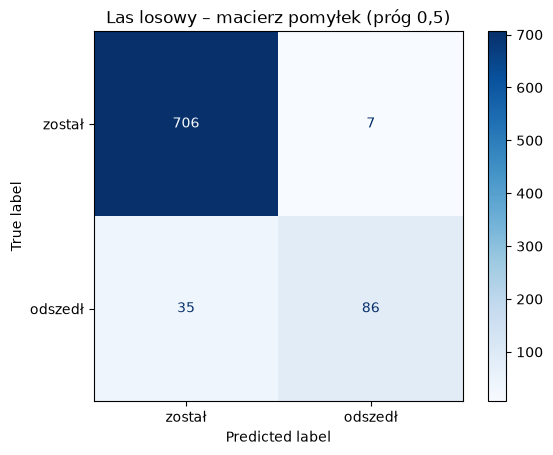

In [6]:
las = modele['las losowy']

ConfusionMatrixDisplay.from_estimator(las, X_test, y_test, display_labels=['został', 'odszedł'], cmap='Blues')
plt.title('Las losowy – macierz pomyłek (próg 0,5)')
plt.show()

Las losowy zwraca prawdopodobieństwo odejścia (`predict_proba`), więc możemy sami wybrać **próg decyzyjny** (domyślnie 0,5). Niższy próg wykryje więcej odchodzących klientów (wyższy recall), kosztem większej liczby fałszywych alarmów (niższy precision), jak w rozdziale 3.2.

In [7]:
proba = las.predict_proba(X_test)[:, 1]

wiersze = []
for prog in [0.2, 0.3, 0.4, 0.5, 0.6]:
    y_pred_prog = (proba >= prog).astype(int)
    wiersze.append({'próg': prog,
                    'precision': precision_score(y_test, y_pred_prog, zero_division=0),
                    'recall': recall_score(y_test, y_pred_prog),
                    'F1': f1_score(y_test, y_pred_prog),
                    'liczba alarmów': int(y_pred_prog.sum())})
pd.DataFrame(wiersze).set_index('próg').round(3)

,precision,recall,F1,liczba alarmów
próg,,,,
0.2,0.625,0.826,0.712,160
0.3,0.772,0.810,0.790,127
0.4,0.889,0.793,0.838,108
0.5,0.925,0.711,0.804,93
0.6,0.931,0.669,0.779,87


Wybór progu to decyzja biznesowa: czy ważniejsze jest wychwycenie jak największej liczby odchodzących klientów, czy ograniczenie kosztów kontaktu z klientami, którzy i tak by zostali.

## 4. Ważność cech

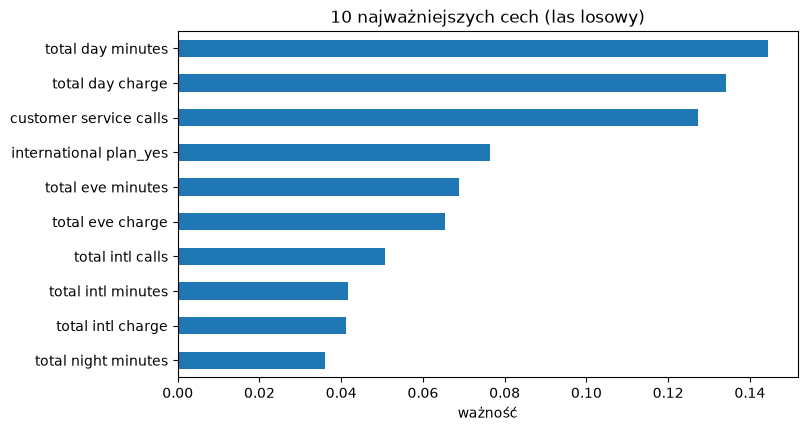

In [8]:
waznosc = pd.Series(las.feature_importances_, index=X.columns).sort_values().tail(10)
waznosc.plot.barh(figsize=(8, 4.5), title='10 najważniejszych cech (las losowy)')
plt.xlabel('ważność')
plt.show()

Na czele są zwykle cechy związane z **czasem rozmów w ciągu dnia**, **kontaktami z obsługą klienta** i **planem międzynarodowym** – podobnie jak w drzewie z rozdziału 4.1, ale las wykorzystuje ich więcej i ważność jest rozłożona bardziej równomiernie. Pamiętajmy, że `total day minutes` i `total day charge` są niemal identyczne (opłata proporcjonalna do minut), więc **dzielą się ważnością**.

## 5. Dobór hiperparametrów (`RandomizedSearchCV`)

Las ma wiele hiperparametrów, więc pełna siatka (`GridSearchCV`) byłaby kosztowna. `RandomizedSearchCV` losuje zadaną liczbę kombinacji (`n_iter`) z podanych zakresów i ocenia je walidacją krzyżową. Jako metrykę wybieramy `f1`, bo dane są niezbalansowane.

In [9]:
rozklady = {
    'n_estimators': randint(100, 500),
    'max_depth': [None, 8, 12, 16, 24],
    'min_samples_leaf': randint(1, 8),
    'min_samples_split': randint(2, 12),
    'max_features': ['sqrt', 'log2', 0.5],
    'class_weight': [None, 'balanced_subsample'],
}

rs = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_distributions=rozklady,
                        n_iter=20, scoring='f1', cv=5, n_jobs=-1, random_state=42)
rs.fit(X_train, y_train)

print('Najlepszy F1 (walidacja krzyżowa):', round(rs.best_score_, 3))
print('Najlepsze parametry:')
for nazwa, wartosc in rs.best_params_.items():
    print(f'  {nazwa}: {wartosc}')

Najlepszy F1 (walidacja krzyżowa): 0.834
Najlepsze parametry:
  class_weight: None
  max_depth: 12
  max_features: log2
  min_samples_leaf: 1
  min_samples_split: 5
  n_estimators: 149


In [10]:
najlepszy = rs.best_estimator_

pd.DataFrame([metryki('las losowy (domyślny)', modele['las losowy']),
              metryki('las losowy (po RandomizedSearchCV)', najlepszy)]).set_index('model').round(3)

,accuracy,precision,recall,F1,ROC-AUC
model,,,,,
las losowy (domyślny),0.950,0.925,0.711,0.804,0.898
las losowy (po RandomizedSearchCV),0.948,0.915,0.711,0.800,0.903


W tym przypadku strojenie **nie poprawiło** wyniku na zbiorze testowym (różnice mieszczą się w granicach szumu) – to cecha lasu losowego: **dobrze działa od ręki**, a zysk ze strojenia bywa niewielki. Wynik końcowy oceniamy na zbiorze testowym, który nie brał udziału w doborze parametrów. Rzetelniejszą ocenę niż jeden podział dałaby walidacja krzyżowa (rozdział 4.4), a wyczerpujące przeszukiwanie – rozdział 4.5.

## 6. Podsumowanie

1. Las losowy dał **wyraźnie lepszy wynik** niż pojedyncze drzewa (F1 ok. 0,80, ROC-AUC ok. 0,90) przy ustawieniach domyślnych.
2. Przy danych niezbalansowanych oceniamy model przez **precision, recall, F1 i ROC-AUC**, a nie `accuracy`.
3. Prawdopodobieństwa z `predict_proba` pozwalają **dobrać próg decyzyjny** do kosztów biznesowych.
4. Ważność cech z lasu pokazuje, co wpływa na odejścia klientów, ale cechy skorelowane dzielą się ważnością.
5. `RandomizedSearchCV` przeszukuje przestrzeń hiperparametrów szybciej niż pełna siatka.
6. Cena za dokładność lasu to **mniejsza interpretowalność** niż pojedynczego drzewa – do wyjaśniania modeli wrócimy w rozdziale 4.6.